step 1 google mount

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Step 1 — Load the dataset in Google Colab

In [ ]:
!pip install pyarrow

Step 2 — Read the dataset

In [ ]:
import pandas as pd

df = pd.read_parquet('/content/data.parquet')

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (100000, 17)

Column Names:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date sent to company', 'Timely response?', 'Consumer disputed?', 'Company response to consumer']


Step 3 — Check the target column

In [ ]:
print(df['Consumer disputed?'].value_counts(dropna=False))

Consumer disputed?
No     48671
NaN    39741
Yes    11588
Name: count, dtype: int64


Step 4 — Remove Missing Target Values

In [ ]:
# Remove rows with missing target values

df_clean = df.dropna(subset=['Consumer disputed?']).copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nTarget Distribution:")
print(df_clean['Consumer disputed?'].value_counts())

Original Dataset Shape: (100000, 17)
Cleaned Dataset Shape: (60259, 17)

Target Distribution:
Consumer disputed?
No     48671
Yes    11588
Name: count, dtype: int64


Step 5 — Check Missing Values

In [ ]:
# Check missing values in each column

missing_values = df_clean.isnull().sum()

missing_percentage = (
    df_clean.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_report = missing_report.sort_values(
    by='Missing Percentage',
    ascending=False
)

print(missing_report)

                              Missing Values  Missing Percentage
Tags                                   51869           86.076769
Consumer complaint narrative           47541           78.894439
Company public response                44876           74.471863
Consumer consent provided?             36923           61.273835
Sub-issue                              35798           59.406894
Sub-product                            18504           30.707446
ZIP code                                3545            5.882939
State                                    431            0.715246
Date received                              0            0.000000
Company                                    0            0.000000
Issue                                      0            0.000000
Product                                    0            0.000000
Submitted via                              0            0.000000
Date sent to company                       0            0.000000
Timely response?         

Step 6 — Check Duplicate Records

In [ ]:
# Check duplicate records

duplicate_count = df_clean.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 97


Step 7 — Remove Duplicate Records

In [ ]:
# Remove duplicate records

df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df_clean.shape)

print("Remaining Duplicate Records:", df_clean.duplicated().sum())

Dataset Shape After Removing Duplicates: (60162, 17)
Remaining Duplicate Records: 0


Step 8 — Check Dataset Information

In [ ]:
# Display dataset information

print("Dataset Information:")
df_clean.info()

print("\nFirst 5 Rows:")
display(df_clean.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 60162 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Date received                 60162 non-null  datetime64[ns]
 1   Product                       60162 non-null  category      
 2   Sub-product                   41742 non-null  category      
 3   Issue                         60162 non-null  object        
 4   Sub-issue                     24378 non-null  object        
 5   Consumer complaint narrative  12715 non-null  object        
 6   Company public response       15333 non-null  category      
 7   Company                       60162 non-null  object        
 8   State                         59731 non-null  category      
 9   ZIP code                      56618 non-null  object        
 10  Tags                          8390 non-null   category      
 11  Consumer con

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Timely response?,Consumer disputed?,Company response to consumer
0,2013-08-30,Bank account or service,Checking account,Deposits and withdrawals,None,None,NaN,WELLS FARGO & COMPANY,MI,39206,"Older American, Servicemember",NaN,Phone,2013-09-17,Yes,No,Closed with explanation
5,2013-12-16,Mortgage,Other mortgage,"Loan modification,collection,foreclosure",None,None,NaN,OCWEN LOAN SERVICING LLC,GA,30022,NaN,NaN,Postal mail,2013-12-19,Yes,No,Closed with explanation
7,2014-12-23,Debt collection,Federal student loan,Improper contact or sharing of info,Contacted employer after asked not to,None,NaN,"National Enterprise Systems, Inc.",FL,335XX,NaN,NaN,Web,2014-12-23,Yes,Yes,Closed with explanation
12,2016-07-14,Credit card,NaN,Transaction issue,None,None,NaN,AMERICAN EXPRESS COMPANY,CA,91744,NaN,Consent not provided,Web,2016-07-14,Yes,No,Closed with non-monetary relief
13,2015-01-15,Debt collection,"Other (i.e. phone, health club, etc.)",Cont'd attempts collect debt not owed,Debt is not mine,None,NaN,AFNI INC.,FL,32765,Older American,NaN,Web,2015-01-15,Yes,No,Closed with explanation


Step 9 — Identify Important Columns

In [ ]:
# Display all column names

print("Total Columns:", len(df_clean.columns))

print("\nAvailable Columns:")
for col in df_clean.columns:
    print(col)
    print("Target Column: Consumer disputed?")
    print(df_clean['Consumer disputed?'].value_counts())

Total Columns: 17

Available Columns:
Date received
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Product
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Sub-product
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Issue
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Sub-issue
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Consumer complaint narrative
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Company public response
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
Company
Target Column: Consumer disputed?
Consumer disputed?
No     48583
Yes    11579
Name: count, dtype: int64
State
Targe

Step 10 — Select Important Features

In [ ]:
# Display important project features

target_column = 'Consumer disputed?'

selected_columns = [
    col for col in [
        'Product',
        'Issue',
        'Sub-issue',
        'Consumer complaint narrative',
        'Company',
        'State',
        'Submitted via',
        'Company response to consumer',
        'Timely response?',
        'Consumer disputed?'
    ]
    if col in df_clean.columns
]

print("Selected Columns:")
print(selected_columns)

print("\nNumber of Selected Columns:", len(selected_columns))

Selected Columns:
['Product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company', 'State', 'Submitted via', 'Company response to consumer', 'Timely response?', 'Consumer disputed?']

Number of Selected Columns: 10


Step 11 — Create the Final Dataset

In [ ]:
# Remove columns that may cause data leakage

remove_columns = [
    'Company response to consumer',
    'Timely response?'
]

feature_columns = [
    col for col in selected_columns
    if col not in remove_columns
    and col != 'Consumer disputed?'
]

# Create final dataset
df_model = df_clean[feature_columns + ['Consumer disputed?']].copy()

print("Final Dataset Shape:", df_model.shape)

print("\nFinal Features:")
print(feature_columns)

print("\nTarget Column:")
print('Consumer disputed?')

display(df_model.head())

Final Dataset Shape: (60162, 8)

Final Features:
['Product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company', 'State', 'Submitted via']

Target Column:
Consumer disputed?


,Product,Issue,Sub-issue,Consumer complaint narrative,Company,State,Submitted via,Consumer disputed?
0,Bank account or service,Deposits and withdrawals,None,None,WELLS FARGO & COMPANY,MI,Phone,No
5,Mortgage,"Loan modification,collection,foreclosure",None,None,OCWEN LOAN SERVICING LLC,GA,Postal mail,No
7,Debt collection,Improper contact or sharing of info,Contacted employer after asked not to,None,"National Enterprise Systems, Inc.",FL,Web,Yes
12,Credit card,Transaction issue,None,None,AMERICAN EXPRESS COMPANY,CA,Web,No
13,Debt collection,Cont'd attempts collect debt not owed,Debt is not mine,None,AFNI INC.,FL,Web,No


Step 12 — Handle Missing Values

In [ ]:
# Handle missing values

for col in feature_columns:
    if isinstance(df_model[col].dtype, pd.CategoricalDtype):
        # Add 'Unknown' to the category list if it is not already present
        if 'Unknown' not in df_model[col].cat.categories:
            df_model[col] = df_model[col].cat.add_categories('Unknown')
    df_model[col] = df_model[col].fillna('Unknown')

print("Missing Values After Cleaning:")
print(df_model.isnull().sum())

print("\nFinal Dataset Shape:", df_model.shape)

Missing Values After Cleaning:
Product                         0
Issue                           0
Sub-issue                       0
Consumer complaint narrative    0
Company                         0
State                           0
Submitted via                   0
Consumer disputed?              0
dtype: int64

Final Dataset Shape: (60162, 8)


Step 13 — Text Cleaning

In [ ]:
import re

# Function to clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Clean complaint narratives
df_model['Consumer complaint narrative'] = (
    df_model['Consumer complaint narrative'].apply(clean_text)
)

print("Text Cleaning Completed!")

print("\nSample Cleaned Complaints:")
display(df_model[['Consumer complaint narrative']].head())

Text Cleaning Completed!

Sample Cleaned Complaints:


,Consumer complaint narrative
0,unknown
5,unknown
7,unknown
12,unknown
13,unknown


Step 14 — Combine Text Features

In [ ]:
# Combine complaint-related text columns

text_columns = [
    'Product',
    'Issue',
    'Sub-issue',
    'Consumer complaint narrative'
]

df_model['Combined_Text'] = df_model[text_columns].agg(
    ' '.join, axis=1
)

print("Text Features Combined Successfully!")

print("\nSample Combined Text:")
display(df_model[['Combined_Text']].head())

Text Features Combined Successfully!

Sample Combined Text:


,Combined_Text
0,Bank account or service Deposits and withdrawa...
5,"Mortgage Loan modification,collection,foreclos..."
7,Debt collection Improper contact or sharing of...
12,Credit card Transaction issue Unknown unknown
13,Debt collection Cont'd attempts collect debt n...


Step 15 — Check Categorical Features

In [ ]:
# Check categorical features

categorical_columns = [
    'Company',
    'State',
    'Submitted via'
]

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique Values:", df_model[col].nunique())
    print(df_model[col].value_counts().head(5))


Company
Unique Values: 2023
Company
BANK OF AMERICA, NATIONAL ASSOCIATION    5239
WELLS FARGO & COMPANY                    4168
EQUIFAX, INC.                            3763
Experian Information Solutions Inc.      3527
JPMORGAN CHASE & CO.                     3366
Name: count, dtype: int64

State
Unique Values: 62
State
CA    8952
FL    5772
TX    4510
NY    3946
GA    2769
Name: count, dtype: int64

Submitted via
Unique Values: 6
Submitted via
Web            40994
Referral       10404
Phone           4007
Postal mail     3899
Fax              833
Name: count, dtype: int64


Step 16 — Prepare Target Variable

In [ ]:
# Convert target labels into numerical values

df_model['Target'] = df_model['Consumer disputed?'].map({
    'No': 0,
    'Yes': 1
})

print("Target Encoding Completed!")

print("\nTarget Distribution:")
print(df_model['Target'].value_counts())

print("\nTarget Mapping:")
print("No = 0")
print("Yes = 1")

print("\nMissing Target Values:", df_model['Target'].isnull().sum())

Target Encoding Completed!

Target Distribution:
Target
0    48583
1    11579
Name: count, dtype: int64

Target Mapping:
No = 0
Yes = 1

Missing Target Values: 0


Step 17 — Prepare Features and Split Data

In [ ]:
from sklearn.model_selection import train_test_split

# Input features
X = df_model[
    ['Combined_Text', 'Company', 'State', 'Submitted via']
]

# Target
y = df_model['Target']

# Remove any rows with invalid target values
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (48129, 4)
Testing Shape: (12033, 4)


Step 18 — TF-IDF Vectorization and Categorical Encoding

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(
            max_features=3000,
            stop_words='english',
            ngram_range=(1, 2)
        ), 'Combined_Text'),

        ('category', OneHotEncoder(
            handle_unknown='ignore'
        ), ['Company', 'State', 'Submitted via'])
    ]
)

print("Preprocessor Created Successfully!")

Preprocessor Created Successfully!


Step 19 — Import Machine Learning Algorithms

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

print("Random Forest and KNN imported successfully!")

Random Forest and KNN imported successfully!


Step 20 — Build Random Forest Model

In [ ]:
# Create a faster Random Forest model

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

print("Optimized Random Forest Model Created!")

Optimized Random Forest Model Created!


Step 21 — Train Random Forest Model

In [ ]:
# Train Random Forest Model

print("Random Forest Training Started...")

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

rf_predictions = rf_model.predict(X_test)

print("Predictions:", rf_predictions[:10])

Random Forest Training Started...
Random Forest Training Completed!
Predictions: [0 0 1 1 1 0 1 1 1 1]


Step 22 — Build and Train KNN Model

In [ ]:
# Import KNN algorithm

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN model
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute',
        weights='distance',
        n_jobs=-1
    ))
])

print("KNN Model Created!")

# Train KNN model
print("\nKNN Training Started...")

knn_model.fit(X_train, y_train)

print("KNN Training Completed!")

# Make predictions
knn_predictions = knn_model.predict(X_test)

print("\nKNN Predictions:", knn_predictions[:10])

KNN Model Created!

KNN Training Started...
KNN Training Completed!

KNN Predictions: [0 0 0 0 0 0 0 0 0 0]


Step 23 — Evaluate Random Forest Model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Random Forest Evaluation

print("RANDOM FOREST MODEL EVALUATION")

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("\nAccuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

RANDOM FOREST MODEL EVALUATION

Accuracy: 0.5433391506689936

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.53      0.65      9717
         Yes       0.24      0.61      0.34      2316

    accuracy                           0.54     12033
   macro avg       0.54      0.57      0.50     12033
weighted avg       0.73      0.54      0.59     12033


Confusion Matrix:
[[5122 4595]
 [ 900 1416]]


Step 24 — Evaluate KNN Model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# KNN Model Evaluation

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN MODEL EVALUATION")

print("\nAccuracy:", knn_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_predictions,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

KNN MODEL EVALUATION

Accuracy: 0.7638161721931356

Classification Report:
              precision    recall  f1-score   support

          No       0.81      0.92      0.86      9717
         Yes       0.26      0.12      0.17      2316

    accuracy                           0.76     12033
   macro avg       0.54      0.52      0.51     12033
weighted avg       0.71      0.76      0.73     12033


Confusion Matrix:
[[8907  810]
 [2032  284]]


Step 25 — Compare Random Forest and KNN

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Compare both models

results = pd.DataFrame({
    'Model': ['Random Forest', 'KNN'],

    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, knn_predictions)
    ],

    'Precision': [
        precision_score(y_test, rf_predictions, zero_division=0),
        precision_score(y_test, knn_predictions, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, rf_predictions, zero_division=0),
        recall_score(y_test, knn_predictions, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, rf_predictions, zero_division=0),
        f1_score(y_test, knn_predictions, zero_division=0)
    ]
})

print("MODEL COMPARISON")
display(results.round(4))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.5433,0.2356,0.6114,0.3401
1,KNN,0.7638,0.2596,0.1226,0.1666


Step 26 — Model Accuracy Visualization

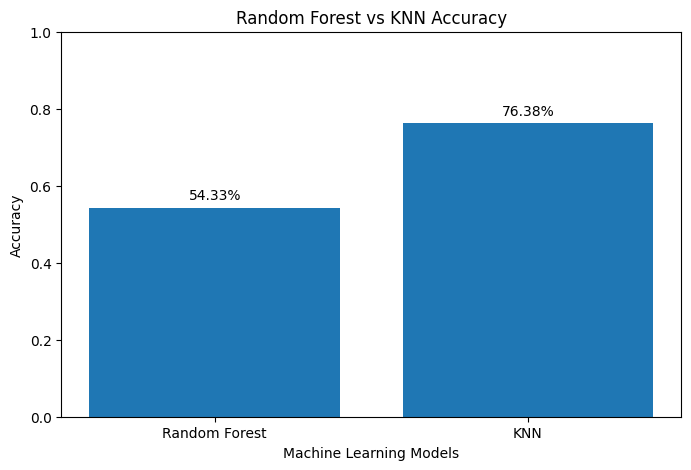

In [ ]:
import matplotlib.pyplot as plt

# Model Accuracy Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['Accuracy']
)

plt.title('Random Forest vs KNN Accuracy')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')

plt.ylim(0, 1)

for i, value in enumerate(results['Accuracy']):
    plt.text(i, value + 0.02, f'{value:.2%}', ha='center')

plt.show()

Step 27 — Random Forest Confusion Matrix Visualization

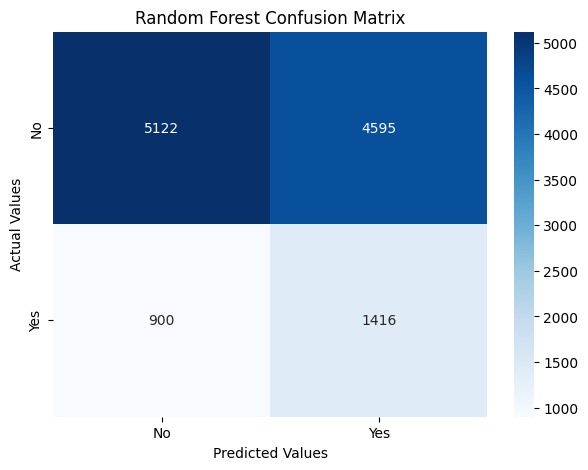

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

Step 28 — Cross-Validation

In [ ]:
from sklearn.model_selection import cross_val_score

# Use a sample to reduce processing time
sample_size = min(10000, len(X_train))

X_cv = X_train.sample(
    n=sample_size,
    random_state=42
)

y_cv = y_train.loc[X_cv.index]

# Perform 3-fold cross-validation
rf_cv_scores = cross_val_score(
    rf_model,
    X_cv,
    y_cv,
    cv=3,
    scoring='f1_macro',
    n_jobs=1
)

print("Cross-Validation Scores:", rf_cv_scores)

print("\nAverage Cross-Validation Score:",
      rf_cv_scores.mean())

Cross-Validation Scores: [0.49818677 0.49092785 0.52815995]

Average Cross-Validation Score: 0.5057581901915781


Step 29 — Save the Best Machine Learning Model

In [ ]:
import joblib
from sklearn.metrics import f1_score

# Calculate F1-scores
rf_f1 = f1_score(
    y_test, rf_predictions, zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_predictions, zero_division=0
)

# Select the model with higher F1-score
if rf_f1 >= knn_f1:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = knn_model
    best_model_name = "KNN"

# Save the selected model
joblib.dump(
    best_model,
    'consumer_complaint_model.pkl'
)

print("Best Model:", best_model_name)
print("Random Forest F1-score:", rf_f1)
print("KNN F1-score:", knn_f1)
print("\nModel Saved Successfully!")

Best Model: Random Forest
Random Forest F1-score: 0.3400984748408791
KNN F1-score: 0.16656891495601173

Model Saved Successfully!


Step 30 — Test the Best Model with a New Complaint

In [ ]:
# Create a new complaint for prediction

new_complaint = pd.DataFrame({
    'Combined_Text': [
        'Credit card company charged an incorrect amount '
        'and did not resolve my payment problem'
    ],
    'Company': ['Unknown'],
    'State': ['CA'],
    'Submitted via': ['Web']
})

# Predict using the best model
prediction = best_model.predict(new_complaint)

print("NEW COMPLAINT PREDICTION")

if prediction[0] == 1:
    print("Result: Consumer Disputed")
else:
    print("Result: Consumer Not Disputed")

NEW COMPLAINT PREDICTION
Result: Consumer Disputed


Step 31 — Create Flask Web Application

In [ ]:
!pip install flask

After installation, create the Flask application:

In [ ]:
%%writefile app.py

from flask import Flask, request, render_template_string
import pandas as pd
import joblib

app = Flask(__name__)

# Load trained machine learning model
model = joblib.load('consumer_complaint_model.pkl')

# Webpage design
html = """
<h1>Consumer Complaint Prediction</h1>

<form method="POST">

    <label>Complaint:</label><br>
    <input type="text" name="complaint" required><br><br>

    <label>Company:</label><br>
    <input type="text" name="company"><br><br>

    <label>State:</label><br>
    <input type="text" name="state"><br><br>

    <label>Submitted Via:</label><br>
    <input type="text" name="submitted"><br><br>

    <button type="submit">Predict</button>

</form>

<h2>{{ result }}</h2>
"""

@app.route('/', methods=['GET', 'POST'])
def home():

    result = ""

    if request.method == 'POST':

        complaint_data = pd.DataFrame({
            'Combined_Text': [request.form['complaint']],
            'Company': [request.form.get('company') or 'Unknown'],
            'State': [request.form.get('state') or 'Unknown'],
            'Submitted via': [
                request.form.get('submitted') or 'Unknown'
            ]
        })

        prediction = model.predict(complaint_data)[0]

        if prediction == 1:
            result = "Consumer Disputed"
        else:
            result = "Consumer Not Disputed"

    return render_template_string(html, result=result)


if __name__ == '__main__':
    app.run(debug=True)

Writing app.py


Step 32 — Create Requirements File

In [ ]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
matplotlib
seaborn
flask
joblib
pyarrow

Writing requirements.txt


Step 33 — Check Project Files

In [ ]:
import os

project_files = [
    'consumer_complaint_model.pkl',
    'app.py',
    'requirements.txt'
]

print("PROJECT FILES CHECK")

for file in project_files:
    if os.path.exists(file):
        print(file, " - Available")
    else:
        print(file, " - Missing")

PROJECT FILES CHECK
consumer_complaint_model.pkl  - Available
app.py  - Available
requirements.txt  - Available


Step 34 — Create Final Project Folder

In [ ]:
import os
import shutil

# Create project folder
project_folder = 'Consumer_Complaint_Prediction'

os.makedirs(project_folder, exist_ok=True)

# Copy project files
files_to_copy = [
    'consumer_complaint_model.pkl',
    'app.py',
    'requirements.txt'
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(file, project_folder)
        print(file, "- Copied Successfully")
    else:
        print(file, "- File Not Found")

print("\nProject Folder Created Successfully!")

consumer_complaint_model.pkl - Copied Successfully
app.py - Copied Successfully
requirements.txt - Copied Successfully

Project Folder Created Successfully!


Step 35 — Create Final ZIP File

In [ ]:
import shutil

# Create ZIP file
zip_file = shutil.make_archive(
    'Consumer_Complaint_Prediction',
    'zip',
    project_folder
)

print("ZIP File Created Successfully!")
print("File Name:", zip_file)

ZIP File Created Successfully!
File Name: /content/Consumer_Complaint_Prediction.zip


Step 36 — Download Your Project

In [ ]:
from google.colab import files

files.download('Consumer_Complaint_Prediction.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Chart 3 — Consumer Dispute Distribution

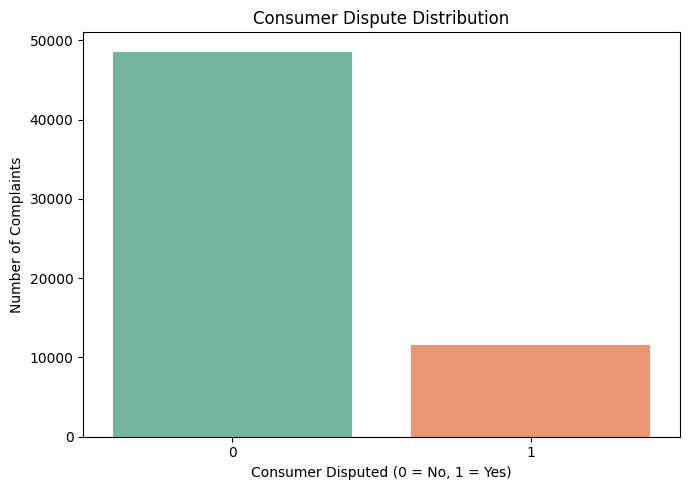

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

target_data = pd.concat([y_train, y_test])

plt.figure(figsize=(7, 5))

sns.countplot(
    x=target_data,
    hue=target_data,
    palette='Set2',
    legend=False
)

plt.title('Consumer Dispute Distribution')
plt.xlabel('Consumer Disputed (0 = No, 1 = Yes)')
plt.ylabel('Number of Complaints')

plt.tight_layout()
plt.show()

Chart 4 — KNN Confusion Matrix

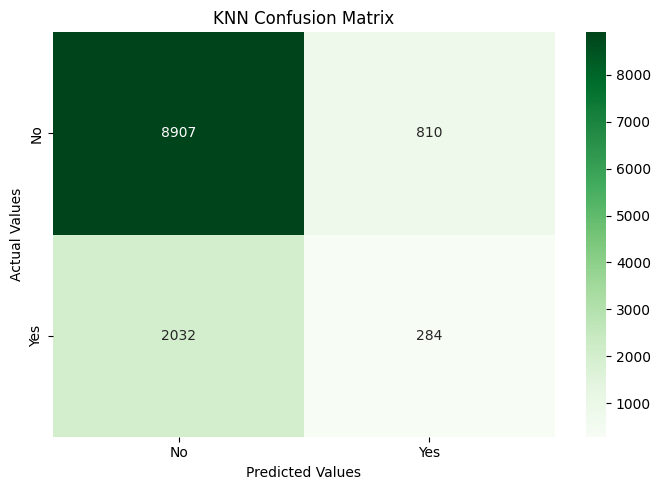

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

knn_cm = confusion_matrix(y_test, knn_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.tight_layout()
plt.show()

Chart 5 — Precision, Recall and F1-score Comparison

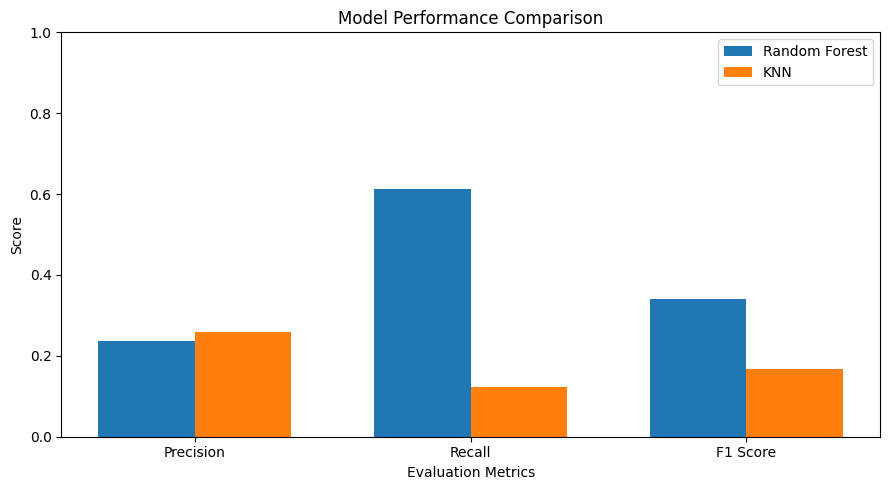

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ['Precision', 'Recall', 'F1 Score']

rf_values = [
    results.loc[0, 'Precision'],
    results.loc[0, 'Recall'],
    results.loc[0, 'F1 Score']
]

knn_values = [
    results.loc[1, 'Precision'],
    results.loc[1, 'Recall'],
    results.loc[1, 'F1 Score']
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, rf_values, width, label='Random Forest')
plt.bar(x + width/2, knn_values, width, label='KNN')

plt.title('Model Performance Comparison')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()

Chart 6 — ROC Curve Comparison

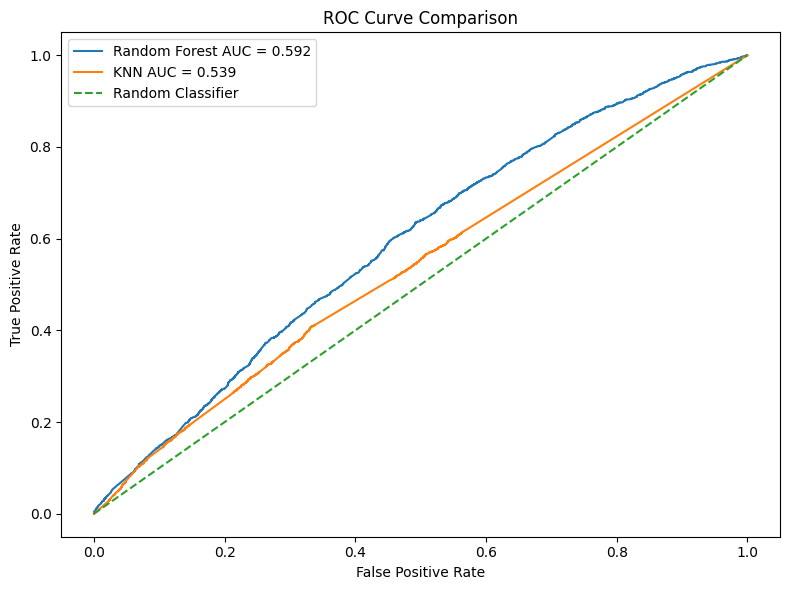

Random Forest ROC-AUC: 0.5917787505578866
KNN ROC-AUC: 0.5393185438052321


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

rf_prob = rf_model.predict_proba(X_test)[:, 1]
knn_prob = knn_model.predict_proba(X_test)[:, 1]

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_prob)

rf_auc = roc_auc_score(y_test, rf_prob)
knn_auc = roc_auc_score(y_test, knn_prob)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest AUC = {rf_auc:.3f}')
plt.plot(knn_fpr, knn_tpr, label=f'KNN AUC = {knn_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.tight_layout()
plt.show()

print("Random Forest ROC-AUC:", rf_auc)
print("KNN ROC-AUC:", knn_auc)

Chart 7 — Model F1-score Comparison

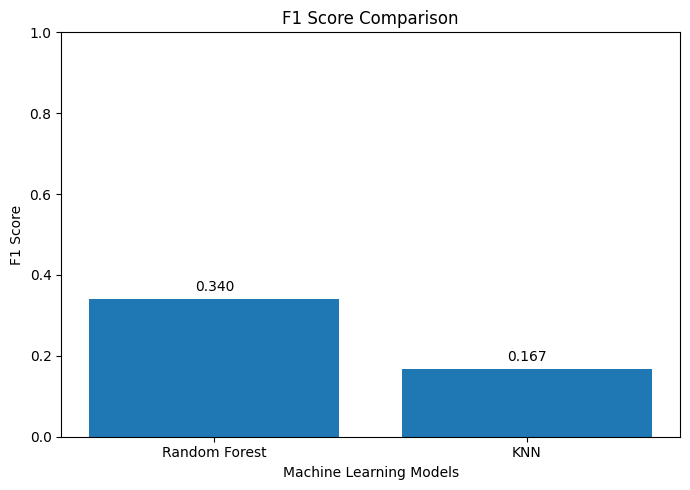

In [ ]:
import matplotlib.pyplot as plt

f1_values = [
    rf_f1,
    knn_f1
]

model_names = ['Random Forest', 'KNN']

plt.figure(figsize=(7, 5))

bars = plt.bar(model_names, f1_values)

plt.title('F1 Score Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('F1 Score')
plt.ylim(0, 1)

for bar, value in zip(bars, f1_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f'{value:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()